# Laboratório do Detector de Objetos
#### Aluno : João Maria de Araujo Nogueira Junior

No Laboratorio a seguir estarei montando um detector de objetos de 4 classes, feito a partir do fine-tuning do YOLO26.

## Primeiro Passo
Primeiramente instalei a biblioteca ultralytics (pra usar o YOLO26), importei as demais bibliotecas e defini alguns hyperparametros da rede como tamanho de batch, numero de epocas, learning rate e o tamanho da imagem de entrada.

In [ ]:
!pip install -q ultralytics

In [ ]:
import os
import glob
import random
import yaml
import zipfile
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.metrics import ConfusionMatrixDisplay

from ultralytics import YOLO

device = 0 if torch.cuda.is_available() else "cpu"

dataset_dir = "imgs_yolo26"           # usei o roboflow pra criar esse dataset
original_yaml = f"{dataset_dir}/data.yaml"

imgsz = 512
batch_size = 16
num_epochs = 50
lr = 1e-3

random.seed(42)
print(f"Dispositivo: {device}")

Dispositivo: 0


## importação
Carrega-se aqui o dataset no formato YOLO. Caso ele ainda não esteja disponível no ambiente, faço o upload do arquivo compactado. Em seguida, leio as classes e organizo os caminhos das imagens e seus rótulos, separados em treino, validação e teste.

In [ ]:
if not os.path.isdir(dataset_dir):
    from google.colab import files

    uploaded = files.upload()

    for name in uploaded:
        with zipfile.ZipFile(name) as z:
            z.extractall(dataset_dir)

print(os.listdir(dataset_dir))

['README.roboflow.txt', 'train', 'test', 'valid', '.ipynb_checkpoints', 'data.yaml', 'data_yolo26.yaml']


In [ ]:

with open(original_yaml) as file_descriptor:
    class_names = yaml.safe_load(file_descriptor)["names"]

classes = [class_names[index] for index in sorted(class_names)] if isinstance(class_names, dict) else list(class_names)
num_classes = len(classes)

split_folders = {"train": "train", "val": "valid", "test": "test"}


def label_path_of(image_path):
    return os.path.splitext(image_path.replace("/images/", "/labels/"))[0] + ".txt"


def read_label_ids(image_path):
    with open(label_path_of(image_path)) as file_descriptor:
        return [int(line.split()[0]) for line in file_descriptor if line.strip()]


split_images = {}
for split_name, folder_name in split_folders.items():
    file_paths = glob.glob(f"{dataset_dir}/{folder_name}/images/*")
    split_images[split_name] = sorted(path for path in file_paths if path.lower().endswith((".jpg", ".jpeg", ".png", ".webp")))

images = [path for paths in split_images.values() for path in paths]
labels = [read_label_ids(path) for path in images]
main_labels = [max(set(label_ids), key=label_ids.count) if label_ids else -1 for label_ids in labels]

class_to_idx = {name: index for index, name in enumerate(classes)}

print(class_to_idx)
print(f"Total de imagens: {len(images)}")
print(f"Total de objetos: {sum(len(label_ids) for label_ids in labels)}")

{'insects': 0, 'mushrooms': 1, 'trees': 2, 'wizards': 3}
Total de imagens: 99
Total de objetos: 750


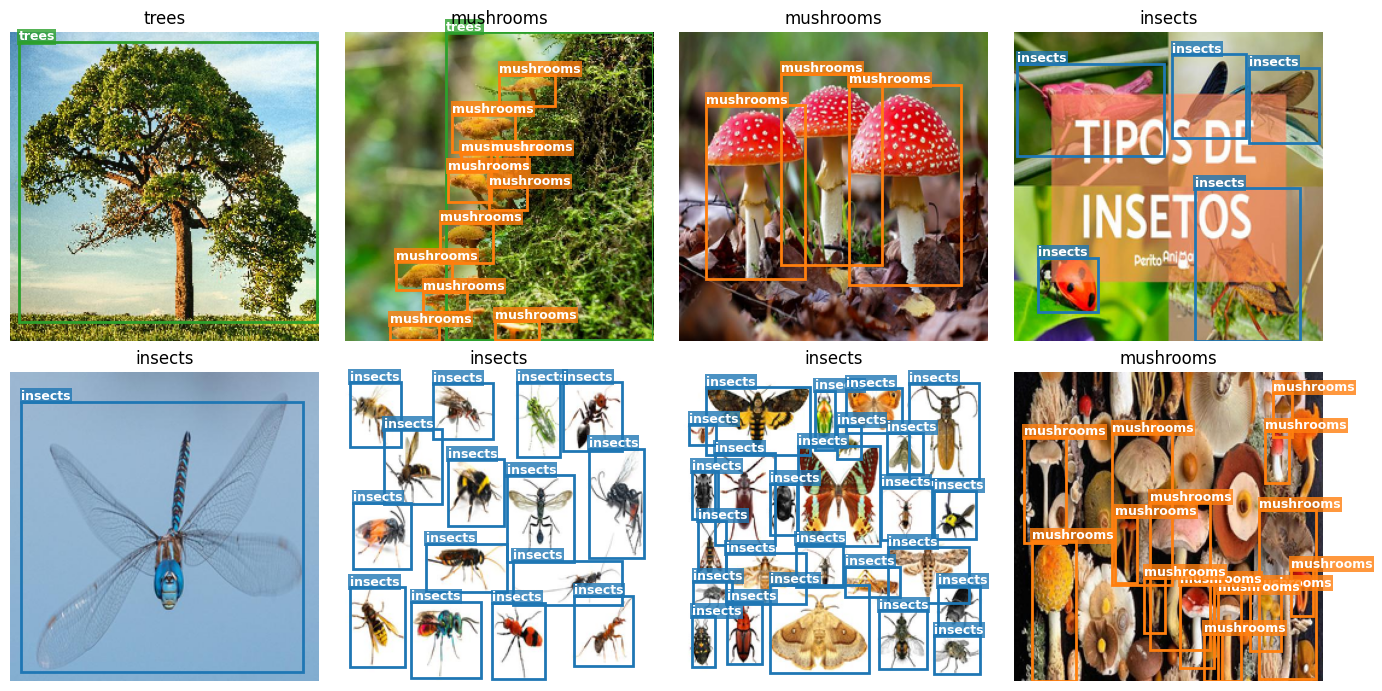

In [ ]:
def draw_yolo_boxes(ax, image, label_path):#draw boxes is working OMG LFMAO
    w, h = image.size
    ax.imshow(image)

    with open(label_path) as f:
        for line in f:
            if not line.strip():
                continue
            c, xc, yc, bw, bh = line.split()
            c = int(c)
            x1, y1 = (float(xc) - float(bw) / 2) * w, (float(yc) - float(bh) / 2) * h

            color = plt.cm.tab10(c)
            ax.add_patch(patches.Rectangle((x1, y1), float(bw) * w, float(bh) * h,
                                           fill=False, edgecolor=color, linewidth=2))
            ax.text(x1, y1 - 3, classes[c], color="white", fontsize=9, fontweight="bold",
                    bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))


fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax in axes.flat:
    idx = random.randrange(len(images))

    image = Image.open(images[idx]).convert("RGB")

    draw_yolo_boxes(ax, image, label_path_of(images[idx]))
    ax.set_title(classes[main_labels[idx]] if main_labels[idx] >= 0 else "sem objetos")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Divisão de Treinamento, Validação e Teste
A divisão das imagens em treinamento, validação e teste já foi feita no Roboflow. Aqui eu apenas utilizo os conjuntos e confiro a quantidade de imagens.

eu dou uma mudada no data.yaml pq o caminho anterior acabou quebrando e eu não consegui resolver isso.

In [ ]:
X_train = split_images["train"]
X_val = split_images["val"]
X_test = split_images["test"]

print(f"Treino: {len(X_train)}")
print(f"Validação: {len(X_val)}")
print(f"Teste: {len(X_test)}")

#objetos de cada classe em cada conjunto
count = pd.DataFrame({
    split: [sum(read_label_ids(p).count(i) for p in paths) for i in range(num_classes)]
    for split, paths in split_images.items()
}, index=classes)
print()
print(count)

Treino: 71
Validação: 18
Teste: 10

           train  val  test
insects      388   22    24
mushrooms    145   15    11
trees         89   13    17
wizards       18    5     3


In [ ]:
data_yaml = os.path.abspath(f"{dataset_dir}/data_yolo26.yaml")

with open(data_yaml, "w") as f:
    yaml.dump({
        "path": os.path.abspath(dataset_dir),
        "train": f"{split_folders['train']}/images",
        "val": f"{split_folders['val']}/images",
        "test": f"{split_folders['test']}/images",
        "names": {i: name for i, name in enumerate(classes)},
    }, f, allow_unicode=True)

print(open(data_yaml).read())

names:
  0: insects
  1: mushrooms
  2: trees
  3: wizards
path: /content/imgs_yolo26
test: test/images
train: train/images
val: valid/images



## Data Augmentation
Diferente do classificador, não preciso normalizar as imagens com a média e desvio do ImageNet, pois o YOLO26 faz o redimensionamento. O data augmentation também é aplicado durante o treino, configurado pelos hiperparâmetros do próprio train().

Reaproveitei algumas transformações que usei antes abaixo.

In [ ]:
aug_args = dict(
    scale=0.5,#zoom
    fliplr=0.5,#espelhamento
    degrees=20,#rotação
    hsv_h=0.015,#matiz
    hsv_s=0.3,#saturação
    hsv_v=0.4,#brilho
    translate=0.1,#deslocamento
    mosaic=1.0,#fusão de imagens...
)

### Visualização do Data Augmentation
Abaixo, uso o próprio gerador de dados do YOLO pra mostrar uma imagem original e 4 versões transformadas dela e alguns exemplos do mosaico, pra melhor visualizar os dados de treino.

In [ ]:
from ultralytics.cfg import get_cfg
from ultralytics.data import build_yolo_dataset
from ultralytics.data.utils import check_det_dataset

data_dict = check_det_dataset(data_yaml)


def make_dataset(mode, **overrides):
    cfg = get_cfg(overrides={"data": data_yaml, "imgsz": imgsz, **aug_args, **overrides})
    return build_yolo_dataset(cfg, data_dict[mode], batch_size, data_dict, mode=mode, stride=32)


def show_sample(ax, sample, title):
    img = sample["img"].permute(1, 2, 0).numpy()
    h, w = img.shape[:2]
    ax.imshow(img)

    for c, (xc, yc, bw, bh) in zip(sample["cls"].view(-1).tolist(), sample["bboxes"].tolist()):
        c = int(c)
        x1, y1 = (xc - bw / 2) * w, (yc - bh / 2) * h
        color = plt.cm.tab10(c)
        ax.add_patch(patches.Rectangle((x1, y1), bw * w, bh * h, fill=False, edgecolor=color, linewidth=2))
        ax.text(x1, y1 - 3, classes[c], color="white", fontsize=8, fontweight="bold",
                bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))

    ax.set_title(title, fontsize=11)
    ax.axis("off")

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 914.7±299.7 MB/s, size: 43.6 KB)
train: Scanning /content/imgs_yolo26/train/labels.cache... 71 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 71/71 12.9Mit/s 0.0s
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 782.0±200.5 MB/s, size: 43.7 KB)
val: Scanning /content/imgs_yolo26/train/labels.cache... 71 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 71/71 9.3Mit/s 0.0s


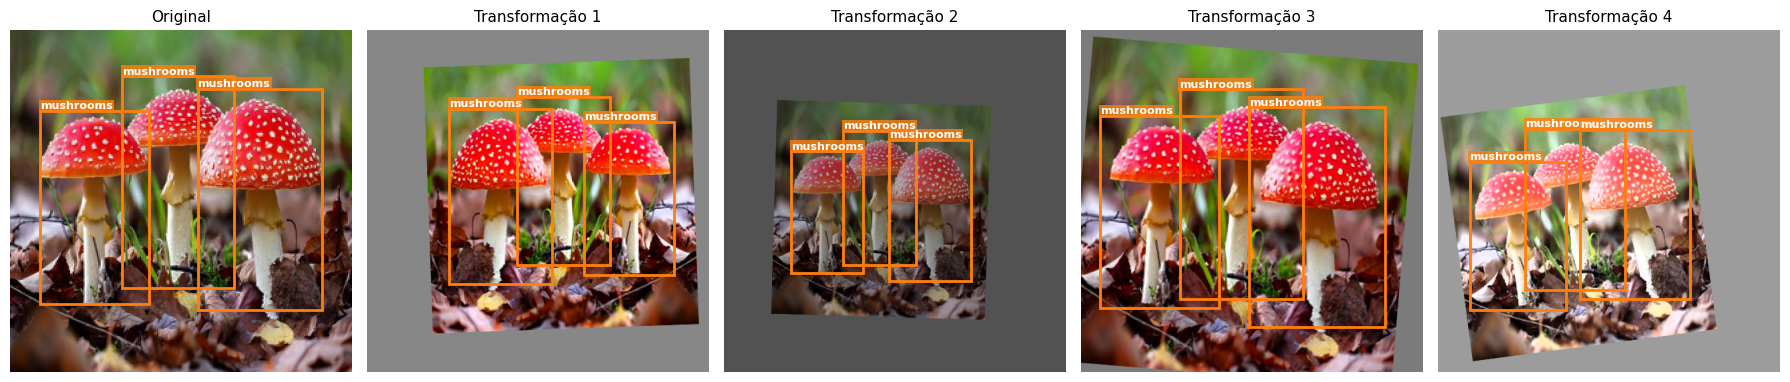

In [ ]:
# sem mosaico
augmented_dataset = make_dataset("train", mosaic=0.0)


random_sample_index = random.randrange(len(augmented_dataset))

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

#original
raw_validation_dataset = build_yolo_dataset(get_cfg(overrides={"data": data_yaml, "imgsz": imgsz}),
                            data_dict["train"], batch_size, data_dict, mode="val", stride=32)  # sem augmentation
show_sample(axes[0], raw_validation_dataset[random_sample_index], "Original")

#aplica transformações
for transformation_index in range(1, 5):
    show_sample(axes[transformation_index], augmented_dataset[random_sample_index], f"Transformação {transformation_index}")

plt.tight_layout()
plt.show()

train: Fast image access ✅ (ping: 0.0±0.0 ms, read: 681.8±171.6 MB/s, size: 36.7 KB)
train: Scanning /content/imgs_yolo26/train/labels.cache... 71 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 71/71 15.7Mit/s 0.0s
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


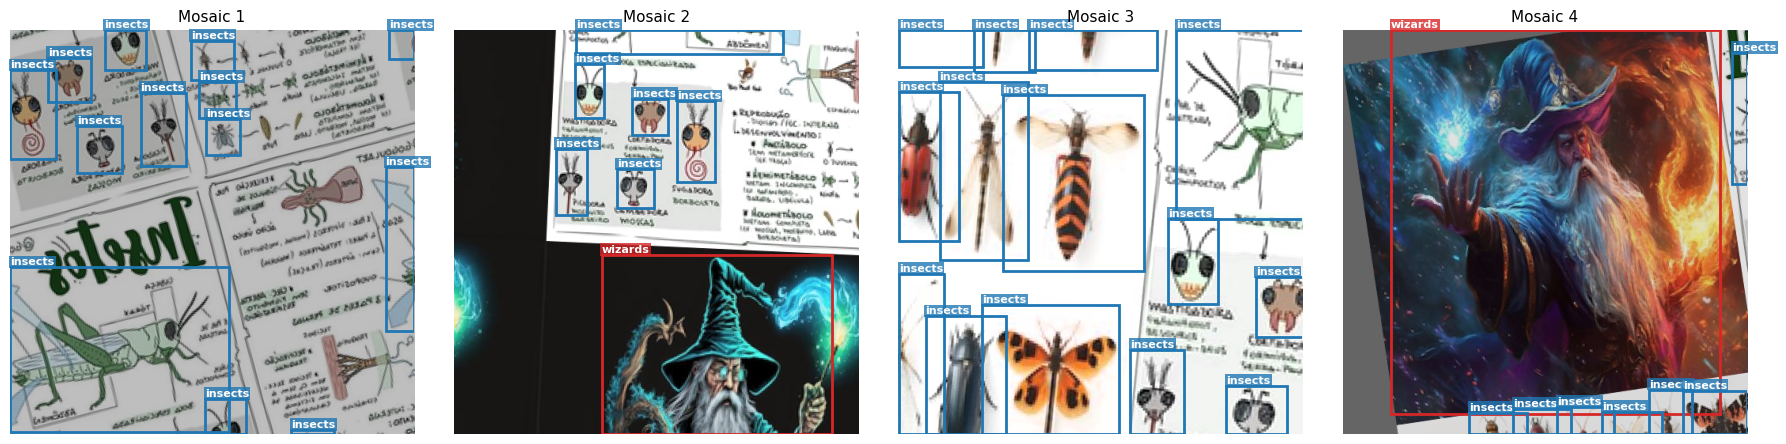

In [ ]:
# com mosaic: 4 imagens combinadas em uma só
mosaic_ds = make_dataset("train", mosaic=1.0)

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for i, ax in enumerate(axes):
    show_sample(ax, mosaic_ds[random.randrange(len(mosaic_ds))], f"Mosaic {i+1}")

plt.tight_layout()
plt.show()

## DataLoaders
Na atividade do laboratorio anterior, eu havia criado uma classe especifica para armazenar o dataset. Aqui o YOLO já traz o seu próprio Dataset, que lê as imagens, os .txt e aplica o augmentation, só preciso criar os DataLoaders que vão agrupar as imagens nos batches. O próprio model.train() aparentemente cria os seus durante o treino.

In [ ]:
from ultralytics.data import build_dataloader

train_set = make_dataset("train")
val_set = make_dataset("val")
test_set = make_dataset("test")

train_dataloader = build_dataloader(train_set, batch_size, workers=2, shuffle=True)
val_dataloader = build_dataloader(val_set, batch_size, workers=2, shuffle=False)
test_dataloader = build_dataloader(test_set, batch_size, workers=2, shuffle=False)

print(f"batches de treino: {len(train_dataloader)}")
print(f"batches de validação: {len(val_dataloader)}")
print(f"batchs de teste: {len(test_dataloader)}")

batch = next(iter(train_dataloader))
print(f"imagens do batch: {tuple(batch['img'].shape)} | objetos no batch: {len(batch['cls'])}")

train: Fast image access ✅ (ping: 0.4±0.9 ms, read: 1149.2±453.4 MB/s, size: 54.6 KB)
train: Scanning /content/imgs_yolo26/train/labels.cache... 71 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 71/71 14.9Mit/s 0.0s
albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 825.6±223.9 MB/s, size: 57.1 KB)
val: Scanning /content/imgs_yolo26/valid/labels.cache... 18 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 18/18 599.2Kit/s 0.0s
test: Fast image access ✅ (ping: 0.0±0.0 ms, read: 711.4±286.5 MB/s, size: 41.1 KB)
test: Scanning /content/imgs_yolo26/test/labels.cache... 10 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 10/10 2.6Mit/s 0.0s
batches de treino: 5
batches de validação: 2
batchs de teste: 1
imagens do batch: (16, 3, 512, 512) | objetos no batch: 133


#Import do YOLO26
Pra tarefa do laboratório o YOLO em especifico a versão 26 foir importada, suponho que o treino vai ser rapido já que o meu dataset é pequeno. Os pesos vêm pré-treinados sobre COCO, então estarei aplicando o fine-tunning via feature extraction. Assim como fiz com a ResNet18, vou congelar o backbone  e treinar só o neck e a cabeça de detecção, aproveitando as features que o modelo já aprendeu.

In [ ]:
model = YOLO("yolo26n.pt")

# congela as camadas do backbone
freeze_layers = 11

model.info()

YOLO26n summary: 260 layers, 2,572,280 parameters, 0 gradients, 6.2 GFLOPs


(260, 2572280, 0, 6.2396672)

#Treinamento e Validação
O YOLO tem o seu próprio loop de treino e validação (a cada época ele calcula as losses e o mAP no conjunto de validação), então a função train abaixo só chama o model.train() com os hyperparametros que defini.

In [ ]:
def train(model, data_yaml, num_epochs, lr=1e-4):
    model.train(data=data_yaml,epochs=num_epochs,imgsz=imgsz,batch=batch_size,optimizer="AdamW",lr0=lr,freeze=freeze_layers,seed=42,device=device,project=os.path.abspath("runs"),name="yolo26_finetune",exist_ok=True,plots=True,**aug_args)

    # o YOLO salva o histórico de cada época em um csv, dentro da pasta da execução
    global run_dir
    run_dir = str(model.trainer.save_dir)
    df = pd.read_csv(f"{run_dir}/results.csv")
    df.columns = [c.strip() for c in df.columns]
    return df

In [ ]:
history = train(model, data_yaml, num_epochs, lr)

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/imgs_yolo26/data_yolo26.yaml, degrees=20, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=11, hsv_h=0.015, hsv_s=0.3, hsv_v=0.4, imgsz=512, iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo26_finetune, nbs=64, nms=None, opset=None, optimi

In [ ]:
best_model = YOLO(f"{run_dir}/weights/best.pt") #guardando pros proximos testes

## Visualização do desempenho
 O primeiro grafico mostra a evolução das losses de treino e validação, e o segundo mostra os valores de mAP@ 0.5 e mAP@ 0.5:0.95 ao longo das épocas.

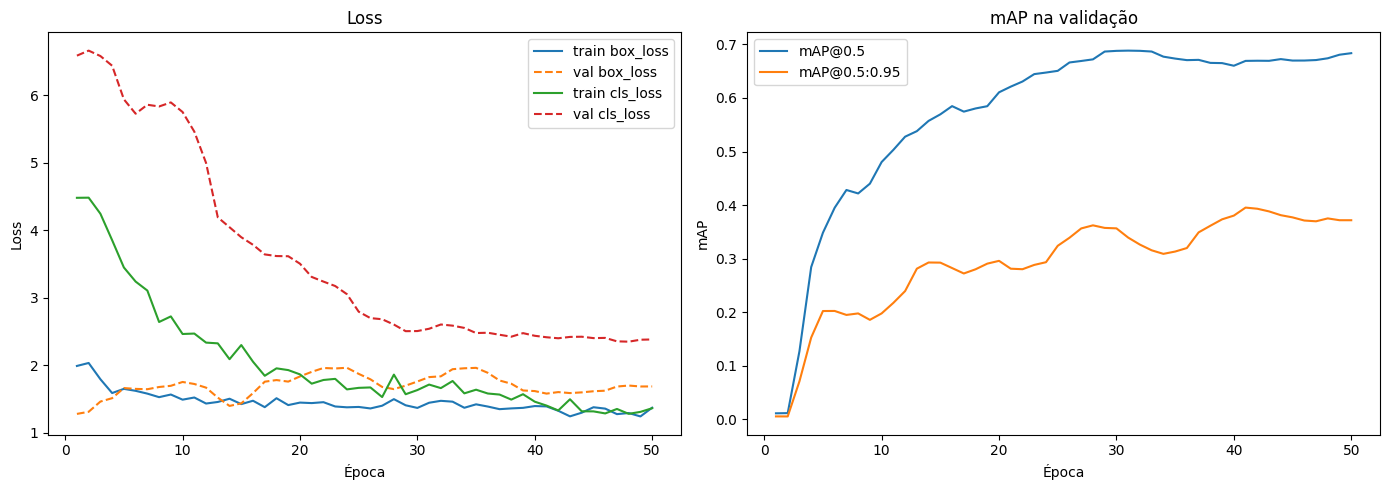

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs = history["epoch"]

for loss in ["box_loss", "cls_loss"]:
    axes[0].plot(epochs, history[f"train/{loss}"], label=f"train {loss}")
    axes[0].plot(epochs, history[f"val/{loss}"], "--", label=f"val {loss}")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].set_title("Loss")
axes[0].legend()

axes[1].plot(epochs, history["metrics/mAP50(B)"], label="mAP@0.5")
axes[1].plot(epochs, history["metrics/mAP50-95(B)"], label="mAP@0.5:0.95")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("mAP")
axes[1].set_title("mAP na validação")
axes[1].legend()

plt.tight_layout()
plt.show()

### Avaliação com mAP
Agora avalio o melhor modelo com o mAP nos conjuntos de validação e de teste (que o modelo nunca viu). A função evaluate devolve precisão, recall, mAP@ 0.5 e mAP@ 0.5:0.95 geral e por classe.

In [ ]:
def evaluate(model, split):
    metrics = model.val(data=data_yaml, split=split, imgsz=imgsz, batch=batch_size,device=device, plots=False, verbose=False)
    per_class = pd.DataFrame({"classe": [classes[i] for i in metrics.ap_class_index],"mAP@0.5": metrics.box.ap50,"mAP@0.5:0.95": metrics.box.ap,}).round(3)
    print(f"[{split}] Precisão: {metrics.box.mp:.3f} | Recall: {metrics.box.mr:.3f} | " f"mAP@0.5: {metrics.box.map50:.3f} | mAP@0.5:0.95: {metrics.box.map:.3f}")
    print(per_class.to_string(index=False))
    print()
    return metrics

val_metrics = evaluate(best_model, "val")
test_metrics = evaluate(best_model, "test")

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,464 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1647.4±426.8 MB/s, size: 47.6 KB)
val: Scanning /content/imgs_yolo26/valid/labels.cache... 18 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 18/18 4.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 4.6it/s 0.4s
                   all         18         55      0.918      0.595       0.67      0.394
Speed: 0.8ms preprocess, 4.7ms inference, 0.0ms loss, 2.8ms postprocess per image
[val] Precisão: 0.918 | Recall: 0.595 | mAP@0.5: 0.670 | mAP@0.5:0.95: 0.394
   classe  mAP@0.5  mAP@0.5:0.95
  insects    0.952         0.494
mushrooms    0.171         0.061
    trees    0.702         0.400
  wizards    0.855         0.622

Ultralytics 8.4.212 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 1491

As losses diminuíram ao longo do treinamento, indicando que o modelo conseguiu aprender. Entretanto, as losses de validação permaneceram acima das de treino.

Já o mAP@ 0.5 chegou a aproximadamente 0.68, enquanto o mAP@ 0.5:0.95 ficou próximo de 0.37. A diferença mostra que o modelo consegue detectar os objetos, mas ainda apresenta dificuldades para localizar as caixas com maior precisão.

Na validação, o modelo apresentou alta precisão, mas um recall moderado, indicando que as detecções realizadas costumam estar corretas, embora alguns objetos não sejam identificados.

Os resultados de mAP foram bastante próximos, indicando que o desempenho se manteve relativamente estável em imagens não utilizadas no treinamento.

Analisando as classes individualmente, os melhores resultados foram para wizards, que apresentou desempenho excelente no teste. No geral, o modelo conseguiu generalizar razoavelmente bem, mas ainda apresenta diferenças de desempenho entre as classes.

### Predições em imagens novas
Por fim, Abaixo pode-se observar predições com imagens que o modelo ainda não viu, seguindo o padrão de plot que utilizei no laboratorio anterior.

In [ ]:
conf_threshold = 0.25  # confiança mínima


def draw_predictions(ax, image, result):
    ax.imshow(image)

    for box, c, conf in zip(result.boxes.xyxy.cpu().numpy(),
                            result.boxes.cls.cpu().numpy().astype(int),
                            result.boxes.conf.cpu().numpy()):
        x1, y1, x2, y2 = box
        color = plt.cm.tab10(c)
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=2))
        ax.text(x1, y1 - 3, f"{classes[c]} {conf:.2f}", color="white", fontsize=9, fontweight="bold",
                bbox=dict(facecolor=color, alpha=0.8, pad=1, edgecolor="none"))

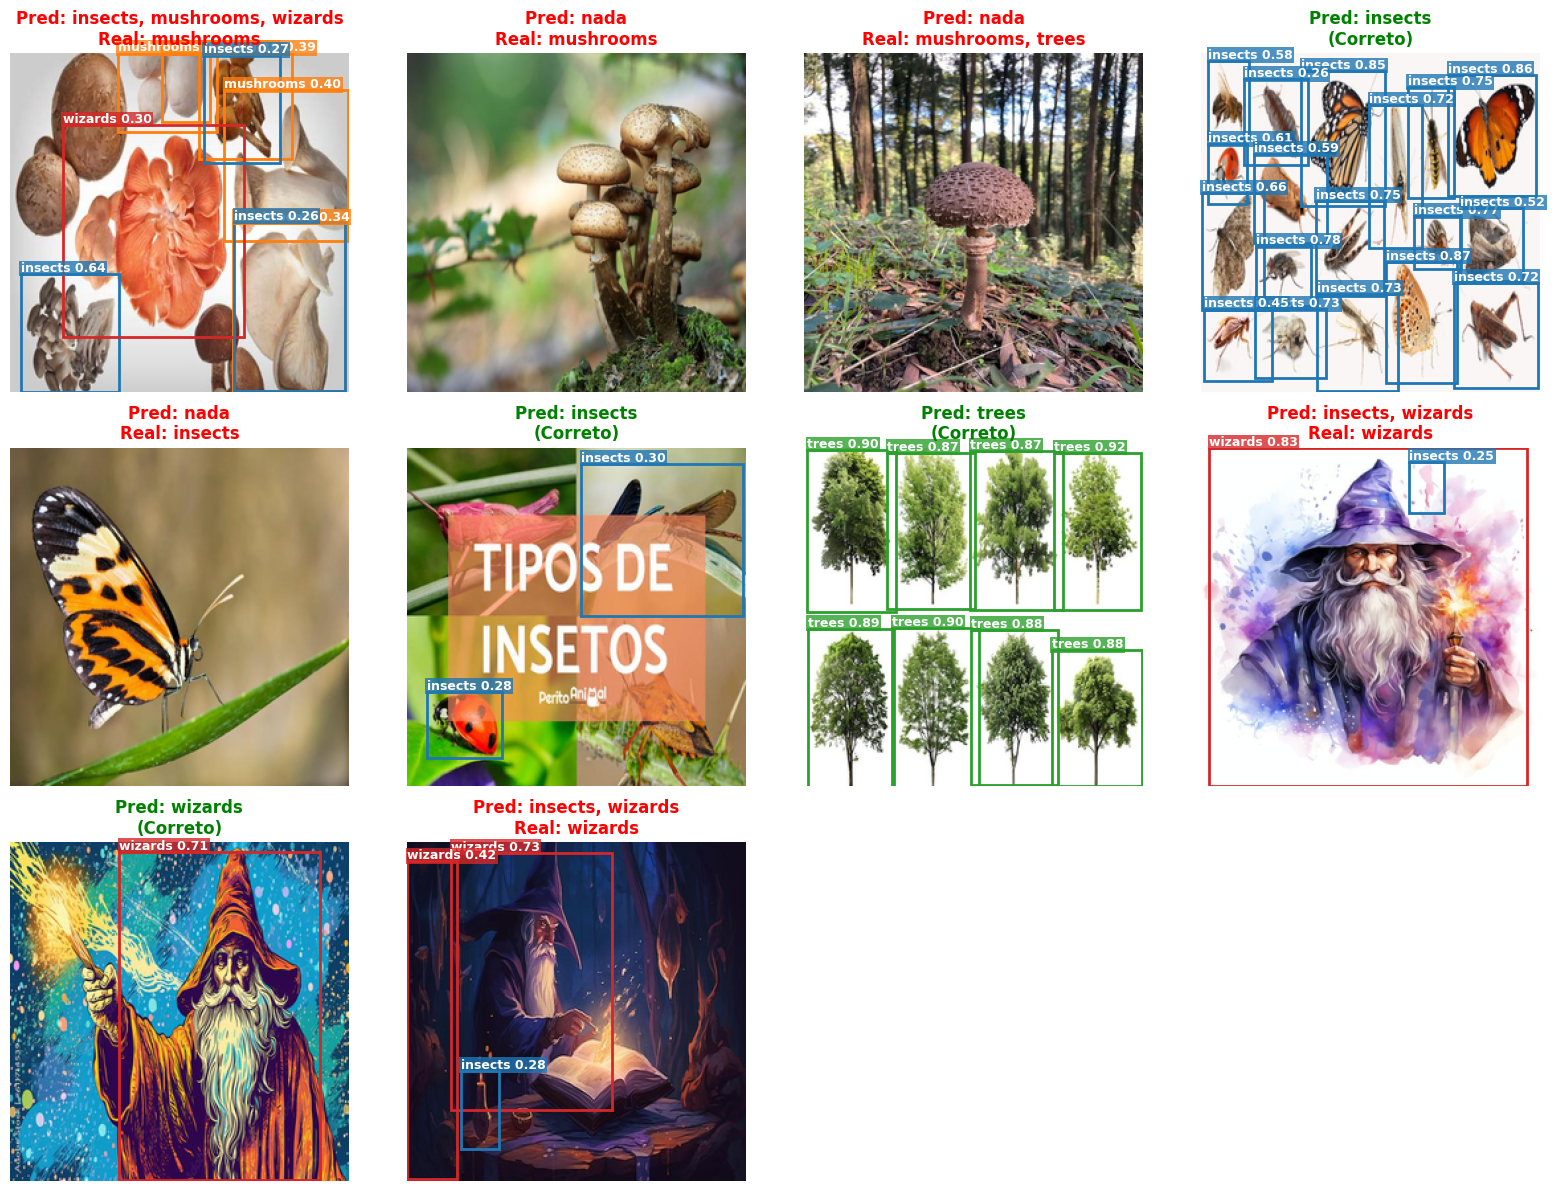

In [ ]:
n_cols = 4
n_rows = -(-len(X_test) // n_cols)  # arredonda pra cima
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4 * n_rows))

for i, ax in enumerate(axes.flat):
    if i >= len(X_test):
        ax.axis('off')
        continue

    #obtem imagem e label originais
    img_path = X_test[i]
    true_classes = {classes[c] for c in read_label_ids(img_path)}

    raw_image = Image.open(img_path).convert("RGB")
    result = best_model.predict(raw_image, imgsz=imgsz, conf=conf_threshold, device=device, verbose=False)[0]

    pred_classes = {classes[int(c)] for c in result.boxes.cls}

    if pred_classes == true_classes:
        title_color = 'green'
        title_text = f"Pred: {', '.join(sorted(pred_classes)) or 'nada'}\n(Correto)"
    else:
        title_color = 'red'
        title_text = f"Pred: {', '.join(sorted(pred_classes)) or 'nada'}\nReal: {', '.join(sorted(true_classes)) or 'nada'}"

    draw_predictions(ax, raw_image, result)
    ax.set_title(title_text, color=title_color, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

No geral, acredito que o modelo não convergiu tão bem quanto o esperado, talvez pela minha inexperiência com as ferramentas de treinamento do Ultralytics e pela falta de dados de treinamento. Felizmente, ao menos o modelo se tornou proficiente na classe *Wizard*. Só é necessário aumentar o threshold de confiança para eliminar as caixas fantasmas que o modelo acabou detectando.

## Testando com a "minha" própria imagem
Para finalizar, usei a biblioteca de upload do próprio colab para enviar uma imagem qualquer (no caso a imagem de um amigo meu) e ver o que o modelo detecta nela.


Saving rn_image_picker_lib_temp_2c3cc617-15c8-4ccd-ba95-3dda32d26e99.webp to rn_image_picker_lib_temp_2c3cc617-15c8-4ccd-ba95-3dda32d26e99 (1).webp


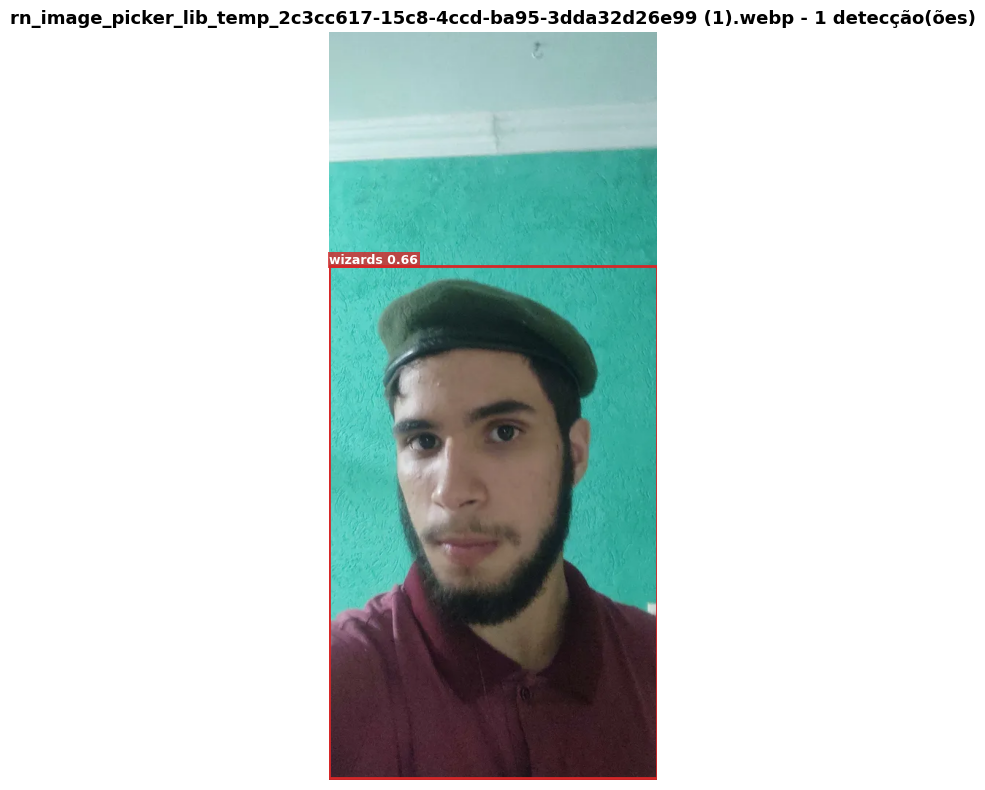

  wizards: 0.66


In [ ]:
from google.colab import files

uploaded = files.upload()  # selecione uma ou mais imagens do seu computador

for name in uploaded:
    image = Image.open(name).convert("RGB")
    result = best_model.predict(image, imgsz=imgsz, conf=conf_threshold, device=device, verbose=False)[0]

    fig, ax = plt.subplots(figsize=(8, 8))
    draw_predictions(ax, image, result)
    ax.set_title(f"{name} - {len(result.boxes)} detecção(ões)", fontsize=13, fontweight='bold')
    ax.axis('off')
    plt.tight_layout()
    plt.show()

    for c, conf in zip(result.boxes.cls.cpu().numpy().astype(int), result.boxes.conf.cpu().numpy()):
        print(f"  {classes[c]}: {conf:.2f}")